# 🧪 LAB: Classifying IoT Device Types with Machine Learning

**Motivation**: The rapid expansion of the Internet of Things (IoT) has dramatically increased the number and diversity of devices connected to modern networks. While these devices bring convenience and functionality, they also introduce new security vulnerabilities. In particular, the presence of unauthorized or malicious IoT devices within a network can pose a serious threat to organizational infrastructure.

To mitigate this risk, it is critical to develop tools that can automatically identify the type of IoT devices connected to a network based on their network traffic behavior. In this lab, you will explore this challenge by building and comparing machine learning models that classify IoT devices by type using real-world network data. 

To this end, in this lab you will be evaluating the effectiveness of different ensemble methods and reflecting on their performance. You will also compare these methods with neural network models.

**Dataset Description**: To do this lab, you will be working with a dataset that contains network traffic features collected from various Internet of Things (IoT) devices operating in a simulated smart home environment. The goal is to automatically identify the type of IoT device connected to the network based on its traffic behavior.

Problem Type: Multi-class classification — identifying which device type (e.g., camera, thermostat) corresponds to a given network traffic sample.

- Instances: 1,800 network traffic captures.

- Features: ~297 attributes per instance, including packet-level and flow-level statistics, protocol usage patterns, temporal and size-based features, categorical indicators (e.g., protocol types)

- Target Variable: device_category — class label indicating the type of IoT device (e.g., 'Light', 'Camera', 'Thermostat', etc.)

---

**Collaboration Note**: This assignment is designed to support collaborative work. We encourage you to divide tasks among group members so that everyone can contribute meaningfully. Many components of the assignment can be approached in parallel or split logically across team members. Good coordination and thoughtful integration of your work will lead to a stronger final result.

---

In total, this lab assignment will be worth **100 points**.

--- 
**Submission notes**:

* Write down all group members' names, or at least the group name (if you have one and you previously provided it), in the first cell of the notebook.

* Verify that the notebook runs as expected and that all required outputs are included.


NAME(s) = "Erik H., Henry Y., Derek W."

## Part 1: Data Preparation and Visualization (15 points)

In this part, you will prepare the data for modeling and explore it using dimensionality reduction techniques.

You should do the following:

1. **Load the data**  
   Load `iot_devices_train.csv` as the training dataset and `iot_devices_reporting.csv` as the reporting dataset.

2. **Separate inputs and outcomes**  
   - The outcome variable corresponds to the `"device_category"` column.  
   - Separate this column from the input features.

3. **Encode the outcome variable**  
   - The outcome variable (type of device) is currently a text variable.  
   - Convert it into numeric values so that each device type is assigned a unique number. Make sure device types are encoded correctly and consistently across the training and reporting sets.
   - *Hint:* You can use `LabelEncoder` from `scikit-learn` for this task.

4. **Dimensionality reduction for visualization**  
   - Apply both PCA and UMAP to reduce the dimensionality of the training set to two dimensions.  
   - Before applying PCA or UMAP, standardize the features. **IMPORTANT:** This standardization is only for the dimensionality reduction visualizations.  
   - Use **pipelines** to apply standardization followed by each dimensionality reduction method.

5. **Visualize the results**  
   - Create two scatter plots (one for PCA, one for UMAP) showing the 2D representations.  
   - Color each point according to its IoT device label.

6. **Compare the methods**  
   - Briefly discuss the differences between the PCA and UMAP visualizations.  
   - What patterns or separations can you observe? Which method seems to give better information about the structure in the data?


In [ ]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.decomposition import PCA
import umap
from sklearn.pipeline import Pipeline

# load data
iot_train = pd.read_csv('iot_devices_train.csv')
iot_report = pd.read_csv('iot_devices_reporting.csv')

# separating 
target_variable_train = iot_train[["device_category"]]
target_variable_report = iot_report[["device_category"]]


# encoding
le = LabelEncoder()
target_variable_train_encoded = le.fit_transform(target_variable_train["device_category"])
target_variable_report_encoded = le.transform(target_variable_report["device_category"])

iot_train = iot_train.drop(columns = "device_category")
iot_report = iot_report.drop(columns = "device_category")

print("Encoded Labels:", target_variable_train_encoded)


Encoded Labels: [4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4
 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4
 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5
 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5
 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5
 5 5 5 5 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7
 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7
 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 8 8 8 8 8 8 8
 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8
 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8
 8 8 8 8 

In [3]:
pipeline_pca = Pipeline([
    ("scaler", StandardScaler()),
    ("reducer", PCA(n_components=2)),
])

pipeline_umap = Pipeline([
    ("scaler", StandardScaler()),
    ("reducer", umap.UMAP(n_components=2, random_state=42)),
])

In [4]:

iot_pca = pipeline_pca.fit_transform(iot_train)
iot_umap = pipeline_umap.fit_transform(iot_train)

print("Reduced shape:", iot_pca.shape)


/opt/miniconda3/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Reduced shape: (900, 2)


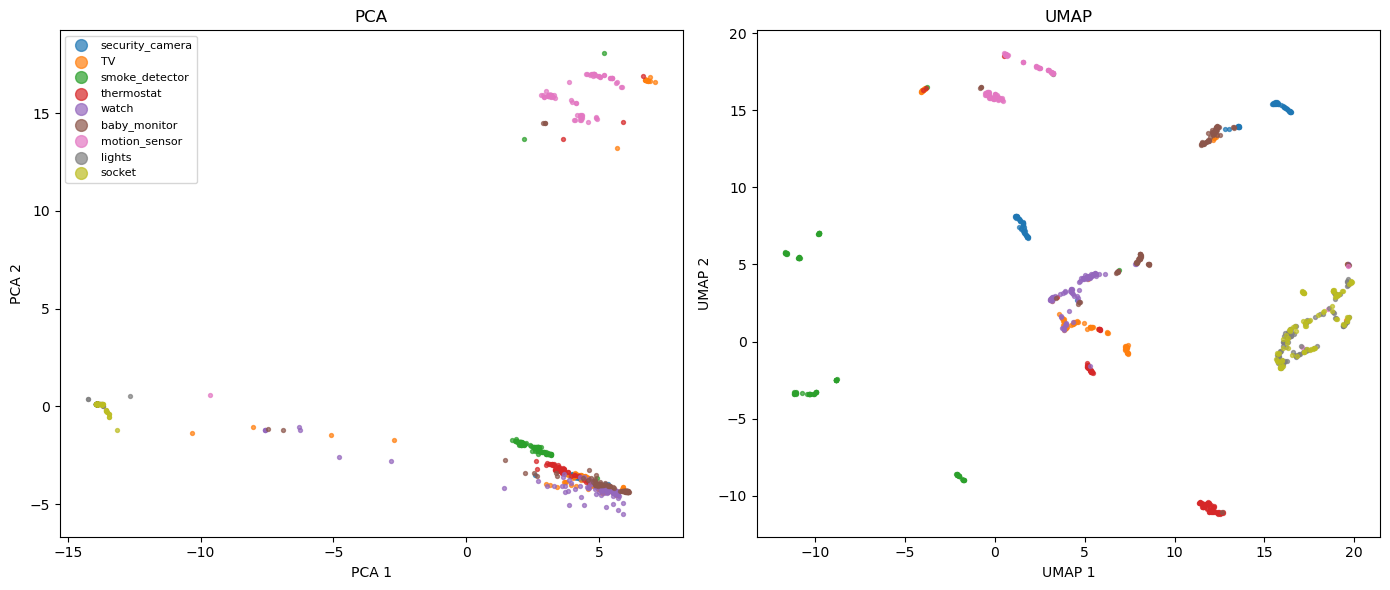

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

labels = target_variable_train["device_category"].to_numpy()

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, emb, title in zip(axes, [iot_pca, iot_umap], ["PCA", "UMAP"]):
    emb = np.asarray(emb)
    assert len(emb) == len(labels), f"{title}: {len(emb)} rows vs {len(labels)} labels"
    for cat in pd.unique(labels):
        mask = labels == cat
        ax.scatter(emb[mask, 0], emb[mask, 1], label=cat, s=8, alpha=0.7)
    ax.set_title(title)
    ax.set_xlabel(f"{title} 1")
    ax.set_ylabel(f"{title} 2")

axes[0].legend(markerscale=3, fontsize=8)
plt.tight_layout()
plt.show()



The Points in PCA are concentrated in three of the corners of the plot, with large groupings of different categories of devices overlapping at the bottom-right (smoke detectors, thermostats, watches, baby monitors). There are also little to no devices with a PCA 1 score between -5 and -0, or devices with a PCA 2 value between 0 and 15. Only really the motion sensors and sockets separate cleanly from the other categories. The points in UMAP are much more spread out, and many of the devices are concentrated in clusters in their own parts of the plot, with exception to a couple (sockets, lights). Some of the categories have multiple clusters too, like motion sensors and baby monitors, meaning that there might be further subdivisions in the types of these devices that PCA doesn't pick up. Ultimately UMAP appears to do a better job at analyzing the structure of the classes of data than PCA does, by spreading the classes across the plot in a non-linear fashion.

## Part 2: Ensemble Methods with Scikit-Learn (40 points)

In this part, you will compare the performance of **Gradient Boosting** and **Random Forests** on the IoT device classification dataset.

Your tasks are:

1. **Pre-analysis Discussion and reflection**  
  Before starting, think about whether the typical preprocessing steps in machine learning (e.g., scaling, normalization, encoding) are necessary for tree-based ensemble methods such as Random Forests and Gradient Boosting. Write a brief explanation of which preprocessing steps (if any) you believe are required for these methods and why, and apply them only if you consider them necessary.

3. **Optimize each model**  
   Train and optimize both models using different combinations of the following hyperparameters:

   - Gradient Boosting: `max_depth`, `learning_rate`  
   - Random Forest: `max_depth`, `max_features`  

   *Tip:* Check the documentation of each model to understand what values make sense for these parameters.

   To ensure a fair comparison:
   - Use the same cross-validation object when optimizing both models.  
   - Use the same candidate values for `max_depth` across models.  
   - To keep the runtime manageable, test only THREE different values for each hyperparameter.  
   - Use a 5-fold cross-validation for tuning.

4. **Evaluate performance**  
   - Use each optimized model to evaluate performance on the reporting data.  
   - Report the accuracy and confusion matrix.
   - Report the total fitting time for the hyperparameter search. To measure it, record the time right before fitting the method and again immediately after it finishes. You can record the time using the `time()` function from the Python package `time`. Then, calculate the difference between the two to obtain the total training time (in minutes).
   - Discuss which types of devices are predicted most accurately and which are more difficult to classify.

5. **Analyze feature importance**  
   - Compare the feature importance resulting from each model. Do this both qualitatively and quantitatively (for example, by examining the similarity between feature importance vectors).
   - Are the most important features consistent across models? Which ones are these? Please, keep this discussion concise but thoughtful—focus on patterns and possible explanations rather than just listing numbers.
    
6. **Reflection**:  How do you think the models performed compared to random guessing?  *Hint:* A baseline accuracy of 50% assumes uniform random guessing between two categories. Since this is a multi-class problem, how should that baseline change?

### 2.1  

Scaling and normalization are generally unnecessary for the tree models because they split the features thresholds. In this lab, it is important to check whether any input columns contain text or missing values, and encode categorical inputs and handle missing values if needed. Moreover, we should double check if there are any learned preprocessing should happen inside the cross-validation pipeline. Following Part 1, we encode the target labels numerically, fitting the label encoder on the training labels and applying the same mapping to the reporting labels. The reporting dataset remains separate and is used only for final evaluation.

In [6]:
# 2.2
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from time import time

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=1234)

max_depth = [3, 5, 7]

# gradient boosting
param_grid_gb = {
    "max_depth": max_depth,
    "learning_rate": [0.03, 0.1, 0.3]
}

gb_search = GridSearchCV(
    estimator=GradientBoostingClassifier(random_state=1234),
    param_grid=param_grid_gb,
    scoring="accuracy",
    cv=cv,
    n_jobs=1,
)

start = time()
gb_search.fit(iot_train, target_variable_train_encoded)
gb_fit_minutes = (time() - start) / 60

print("Best parameters:", gb_search.best_params_)
print("Best CV accuracy:", gb_search.best_score_)
print("Total fitting time (minutes):", gb_fit_minutes)

# random forest
param_grid_rf = {
    "max_depth": max_depth,
    "max_features": ["sqrt", "log2", 0.5]
}

rf_search = GridSearchCV(
    estimator=RandomForestClassifier(random_state=1234),
    param_grid=param_grid_rf,
    scoring="accuracy",
    cv=cv,
    n_jobs=1,
)

start = time()
rf_search.fit(iot_train, target_variable_train_encoded)
rf_fit_minutes = (time() - start) / 60

print("Best parameters:", rf_search.best_params_)
print("Best CV accuracy:", rf_search.best_score_)
print("Total fitting time (minutes):", rf_fit_minutes)

Best parameters: {'learning_rate': 0.3, 'max_depth': 3}
Best CV accuracy: 0.8833333333333334
Total fitting time (minutes): 3.5477850159009297
Best parameters: {'max_depth': 7, 'max_features': 0.5}
Best CV accuracy: 0.8877777777777778
Total fitting time (minutes): 0.08553473154703777


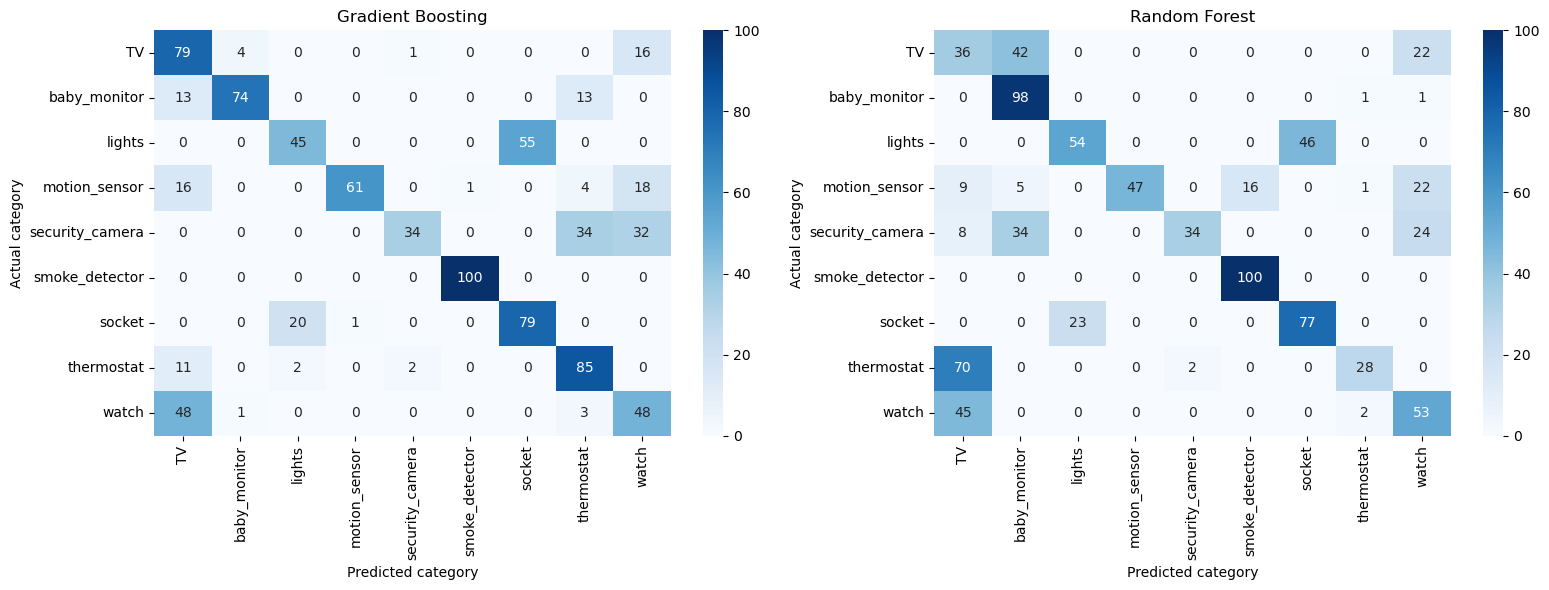

Gradient Boosting accuracy: 67.22%
Random Forest accuracy: 58.56%


In [19]:
# 2.3
from sklearn.metrics import accuracy_score, confusion_matrix
import seaborn as sns

# predictions on reporting data
iot_report_gb = gb_search.best_estimator_.predict(iot_report)
iot_report_rf = rf_search.best_estimator_.predict(iot_report)

# accuracy scores
iot_accuracy_gb = accuracy_score(target_variable_report_encoded, iot_report_gb)
iot_accuracy_rf = accuracy_score(target_variable_report_encoded, iot_report_rf)

# confusion matrices
labels = np.arange(len(le.classes_))

cm_gb = confusion_matrix(
    target_variable_report_encoded, iot_report_gb, labels=labels
)

cm_rf = confusion_matrix(
    target_variable_report_encoded, iot_report_rf, labels=labels
)

# report results
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for ax, cm, title in [
    (axes[0], cm_gb, "Gradient Boosting"),
    (axes[1], cm_rf, "Random Forest"),
]:
    sns.heatmap(
        cm,
        annot=True,                  #
        fmt="d",                     
        cmap="Blues",
        xticklabels=le.classes_,
        yticklabels=le.classes_,
        vmin=0,
        vmax=max(cm_gb.max(), cm_rf.max()),
        ax=ax,
    )

    ax.set_title(title)
    ax.set_xlabel("Predicted category")
    ax.set_ylabel("Actual category")
    ax.tick_params(axis="x", labelrotation=90)
    ax.tick_params(axis="y", labelrotation=0)

plt.tight_layout()
plt.show()


print(f"Gradient Boosting accuracy: {iot_accuracy_gb:.2%}")
print(f"Random Forest accuracy: {iot_accuracy_rf:.2%}")


### 2.3 Interpretation
Gradient Boosting has a higher accuracy than Random Forest on the reporting dataset (67.22% versus 58.56%), but with a much longer search time 3.55 minutes compared with 0.086 minutes. Both models correctly classified all smoke detectors. Gradient Boosting performed well on thermostats, TVs, and sockets, but struggled with security cameras, lights, and watches. Random Forest performed well on baby monitors and sockets, but struggled with thermostats, security cameras, and TVs. Both models scored about 88% during cross-validation but performed worse on the reporting data, which suggests weaker performance on unseen data, possibly because of over-fitting or differences between the datasets.


Gradient Boosting — top 10 features:


,Importance
ttl_avg,0.101388
packet_inter_arrivel_sum,0.084727
http_time_thirdQ,0.079982
ttl_min,0.066242
packet_inter_arrivel_min,0.064172
packet_inter_arrivel_firstQ,0.059286
packet_inter_arrivel_B_min,0.050363
ttl_entropy,0.048022
B_port_is_8080,0.037710
ttl_B_max,0.036109


Random Forest — top 10 features:


,Importance
ttl_min,0.111400
ttl_B_min,0.081763
ttl_B_max,0.075255
ttl_B_avg,0.051931
packet_inter_arrivel_A_sum,0.046719
packet_inter_arrivel_sum,0.042658
packet_inter_arrivel_B_min,0.037858
ttl_A_median,0.024648
ttl_firstQ,0.024279
ttl_B_median,0.023856


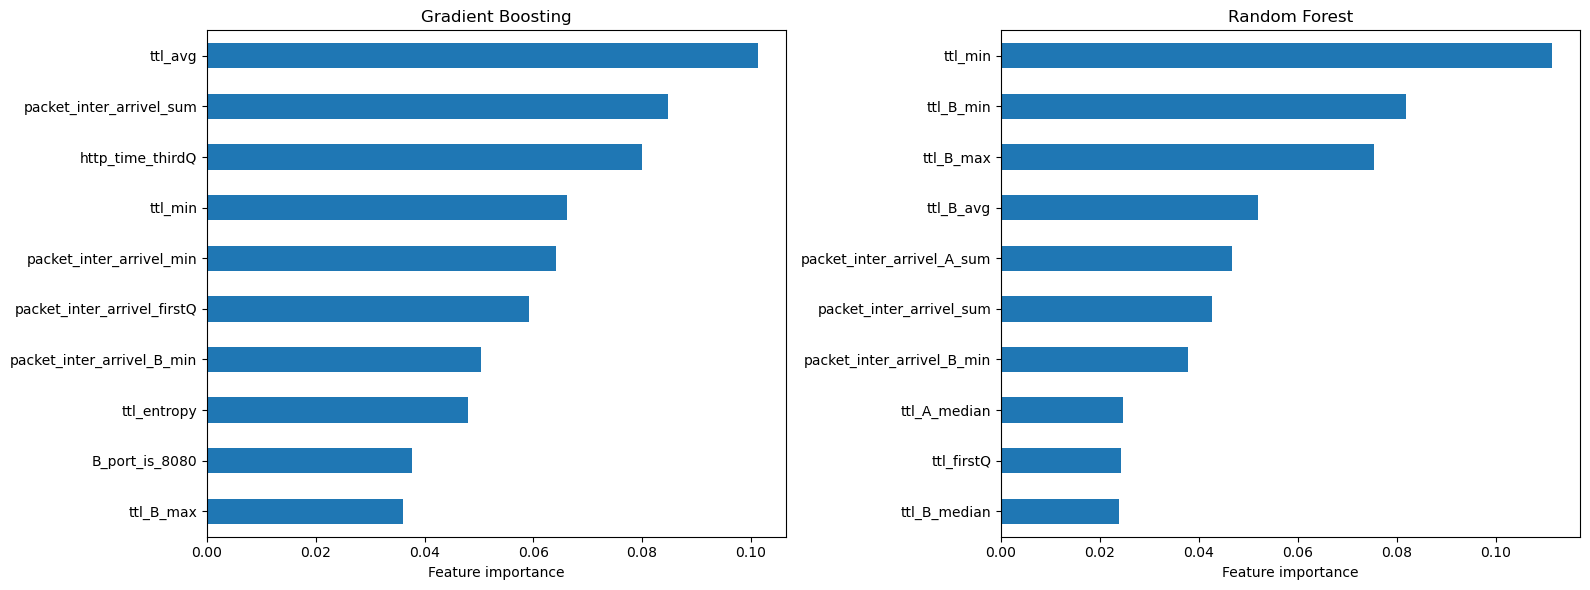

Spearman rank correlation: 0.840
Shared top-10 features: 4 out of 10
Shared features: ['packet_inter_arrivel_B_min', 'packet_inter_arrivel_sum', 'ttl_B_max', 'ttl_min']


In [9]:
# 2.4

# feature importance comparison
importance = pd.DataFrame({
    "Gradient Boosting": gb_search.best_estimator_.feature_importances_,
    "Random Forest": rf_search.best_estimator_.feature_importances_,
}, index=iot_train.columns)

# top 10 features for each model
gb_top10 = importance["Gradient Boosting"].nlargest(10)
rf_top10 = importance["Random Forest"].nlargest(10)

print("Gradient Boosting — top 10 features:")
display(gb_top10.to_frame("Importance"))

print("Random Forest — top 10 features:")
display(rf_top10.to_frame("Importance"))

# visualization
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

gb_top10.sort_values().plot.barh(ax=axes[0], title="Gradient Boosting")
rf_top10.sort_values().plot.barh(ax=axes[1], title="Random Forest")

for ax in axes:
    ax.set_xlabel("Feature importance")

plt.tight_layout()
plt.show()

# compare rankings across all features
rank_correlation = importance.corr(method="spearman").loc[
    "Gradient Boosting", "Random Forest"
]

# compare membership of the top-10 lists
shared_features = sorted(set(gb_top10.index) & set(rf_top10.index))

print(f"Spearman rank correlation: {rank_correlation:.3f}")
print(f"Shared top-10 features: {len(shared_features)} out of 10")
print("Shared features:", shared_features)

### 2.4 Interpretation
Both models mostly agree on which features matter (Spearman correlation of 0.840), but share only four of their top ten features. Both models rely heavily on TTL and the time between packets. Gradient Boosting ranks ttl_avg highest, while Random Forest ranks ttl_min highest and places more emphasis on TTL features overall. These differences may occur because related features provide similar information so that each model can rely on different features to make predictions.


### 2.5 Reflection: comparison with random guessing
Since there are total of nine categories, so a random guessing has an expected accuracy of 1/9, or 11.11% of accuracy rather a 50/50 guess. In our lab, Gradient Boosting scored 67.22% and Random Forest scored 58.56%, so both performed much better than guessing. However, both still struggled with some device types, so there is room for improvement.


## Part 3: Histogram-Based Gradient Boosting (20 points)

Gradient Boosting is a powerful algorithm, but it can also be computationally expensive. To address this limitation, a modern and optimized implementation inspired by *LightGBM* has been introduced (see recommended reading). In `scikit-learn`, this approach is available through `HistGradientBoostingClassifier`.

Here, you will explore how this implementation differs from the traditional `GradientBoostingClassifier`, understand the mechanisms behind its computational efficiency, and apply it to the same dataset used previously.

You should complete the following steps:

1. **Read and summarize**  
   Read the [Histogram-based Gradient Boosting documentation](https://scikit-learn.org/stable/modules/ensemble.html#histogram-based-gradient-boosting), which describes the algorithm and its key differences from `GradientBoostingClassifier`.  

   *Optional (for deeper understanding):*
   - Ke et al. (2017). *[LightGBM: A Highly Efficient Gradient Boosting Decision Tree](https://proceedings.neurips.cc/paper_files/paper/2017/hash/6449f44a102fde848669bdd9eb6b76fa-Abstract.html)*  
   - *[Introduction to Boosted Trees — XGBoost documentation](https://xgboost.readthedocs.io/en/stable/tutorials/model.html)*  

   Then, briefly answer the following questions:  
   - What are the main differences between `HistGradientBoostingClassifier` and `GradientBoostingClassifier`?  
   - How does histogram binning make training faster?

2. **Optimize and train a `HistGradientBoostingClassifier` object from `sklearn.ensemble`**  
   - Use the same approach you applied to Gradient Boosting in Part 2.  
   - Reuse the same `param_grid` from Part 2.  
   - Use `GridSearchCV` for hyperparameter tuning.  
   - Use the same cross-validation object to ensure a fair comparison.

3. **Evaluate the optimized model**  
   - Report the accuracy and confusion matrix.
   - Measure and report the total hyperparameter search time, following the same procedure used in Part 2.
4. **Reflection**  
   - How does this method compare to `GradientBoostingClassifier` in terms of computation time and predictive performance? Discuss any trade-offs you observe.

In [ ]:
# USE AS MANY CELLS AS NEEDED

## Part 4: Neural Network Model (20 points)

In this final part of the assignment, you will revisit neural networks and compare their performance with the ensemble methods explored in the previous parts.

You should do the following:

1. **Preprocessing reflection**  
   - Briefly describe which preprocessing steps are important before training a neural network.  
   - If such steps are necessary in this case, apply them before training your model.

2. **Model optimization and training**  
   - Use NINE different combinations of hidden units and hidden layers as the hyperparameters to tune.
   - Use early stopping to reduce the risk of overfitting.  
   - Train the model for up to 300 epochs.  
   - Use `GridSearchCV` to optimize the model’s hyperparameters.  
   - Make sure to use the same cross-validation object as in Parts 2 and 3 for a fair comparison.  
   - *Tip:* Check the [MLPClassifier documentation](https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPClassifier.html) to see how to enable early stopping and adjust other parameters.

3. **Evaluate performance**  
   - Use the same evaluation metrics as in Parts 2 and 3.  
   - Compare the neural network’s performance with the ensemble models.  
   - Reflect on how model complexity and interpretability differ across methods.

**Constraint:**  
Use `MLPClassifier` from `scikit-learn` for this exercise.


In [ ]:
# USE AS MANY CELLS AS NEEDED

## Part 5: Collaboration Reflection (5 points)

As a group, identify **one specific challenge or inefficiency** you encountered while working on this lab. In 3–5 sentences:

1. Briefly describe what happened and how it affected your work.
2. Identify one concrete action your group will take to avoid or better manage this issue in the next lab.

If your group encountered no major problem, identify one aspect of your collaboration that could still be improved.

YOUR TEXT HERE